# A/B Testing and Customer Segmentation Analysis
## Phases 1–3: Data inspection, cleaning, EDA and A/B testing

Run this notebook in **Google Colab**. Upload your two extracted datasets when prompted:
- `marketing_AB.csv`
- `Online Retail.xlsx`

This notebook completes dataset inspection, cleaning, exploratory analysis for both datasets, and statistical A/B testing for the marketing experiment. It does **not** perform RFM or K-Means yet.

The datasets are separate sources and must not be joined or treated as the same customers.

## 1. Upload both datasets

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd

# Update this path to your Google Drive folder
DATA_PATH = "/content/drive/MyDrive/AB testing"

# Load datasets
marketing_raw = pd.read_csv(
    os.path.join(DATA_PATH, "marketing_AB.csv")
)

retail_raw = pd.read_excel(
    os.path.join(DATA_PATH, "Online Retail.xlsx")
)

print("Marketing dataset:", marketing_raw.shape)
print("Online Retail dataset:", retail_raw.shape)

display(marketing_raw.head())
display(retail_raw.head())

Mounted at /content/drive
Marketing dataset: (588101, 7)
Online Retail dataset: (541909, 8)


,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 2. Imports and output folders

In [ ]:
import re, json, warnings, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import (
    proportions_ztest, proportion_confint,
    confint_proportions_2indep, proportion_effectsize
)
from statsmodels.stats.power import NormalIndPower

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

OUT = Path("outputs")
FIG = OUT / "figures"
MET = OUT / "metrics"
for p in (FIG, MET):
    p.mkdir(parents=True, exist_ok=True)
ALPHA = 0.05

## 3. Find and load files

In [ ]:
import os
import pandas as pd

# Google Drive folder containing your datasets
DATA_PATH = "/content/drive/MyDrive/AB testing"

# Load datasets directly from Google Drive
marketing_file = os.path.join(DATA_PATH, "marketing_AB.csv")
retail_file = os.path.join(DATA_PATH, "Online Retail.xlsx")

marketing_raw = pd.read_csv(marketing_file)
retail_raw = pd.read_excel(retail_file)

print("Marketing dataset:", marketing_raw.shape)
print("Online Retail dataset:", retail_raw.shape)

display(marketing_raw.head())
display(retail_raw.head())

Marketing dataset: (588101, 7)
Online Retail dataset: (541909, 8)


,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.5500,"17,850.0000",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.3900,"17,850.0000",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.7500,"17,850.0000",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.3900,"17,850.0000",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.3900,"17,850.0000",United Kingdom


## 4. Marketing dataset: inspect and clean

In [ ]:
print("Columns:", marketing_raw.columns.tolist())
print("Missing values:\n", marketing_raw.isna().sum())
print("Exact duplicate rows:", marketing_raw.duplicated().sum())

def standardize_marketing_columns(df):
    d = df.copy()
    d = d.loc[:, ~d.columns.astype(str).str.match(r"^Unnamed", case=False)]
    mapping = {
        "userid":"user id", "testgroup":"test group", "converted":"converted",
        "totalads":"total ads", "mostadsday":"most ads day", "mostadshour":"most ads hour"
    }
    rename = {}
    for c in d.columns:
        key = re.sub(r"[^a-z0-9]", "", str(c).lower())
        if key in mapping: rename[c] = mapping[key]
    d = d.rename(columns=rename)
    required = ["user id","test group","converted","total ads","most ads day","most ads hour"]
    missing = [c for c in required if c not in d.columns]
    if missing: raise ValueError(f"Missing columns {missing}. Found {d.columns.tolist()}")
    return d

marketing = standardize_marketing_columns(marketing_raw).drop_duplicates().copy()
marketing["user id"] = pd.to_numeric(marketing["user id"], errors="coerce")
marketing["converted"] = pd.to_numeric(marketing["converted"], errors="coerce")
marketing["total ads"] = pd.to_numeric(marketing["total ads"], errors="coerce")
marketing["most ads hour"] = pd.to_numeric(marketing["most ads hour"], errors="coerce")
marketing["test group"] = marketing["test group"].astype(str).str.strip().str.lower()
marketing["most ads day"] = marketing["most ads day"].astype(str).str.strip()
marketing = marketing[
    marketing["user id"].notna() &
    marketing["test group"].isin(["ad","psa"]) &
    marketing["converted"].isin([0,1])
].copy()
marketing["converted"] = marketing["converted"].astype(int)

# Remove users appearing in both groups; retain one row per remaining user.
conflict_users = marketing.groupby("user id")["test group"].nunique()
conflict_users = conflict_users[conflict_users > 1].index
if len(conflict_users):
    print("Removing users assigned to both groups:", len(conflict_users))
    marketing = marketing[~marketing["user id"].isin(conflict_users)]
dup_users = marketing["user id"].duplicated().sum()
print("Repeated user IDs:", dup_users)
if dup_users:
    marketing = marketing.drop_duplicates("user id", keep="first")
print("Clean marketing shape:", marketing.shape)
display(marketing.groupby("test group").agg(
    users=("user id","nunique"), conversions=("converted","sum"),
    conversion_rate=("converted","mean"), avg_ads_seen=("total ads","mean")
))

Columns: ['Unnamed: 0', 'user id', 'test group', 'converted', 'total ads', 'most ads day', 'most ads hour']
Missing values:
 Unnamed: 0       0
user id          0
test group       0
converted        0
total ads        0
most ads day     0
most ads hour    0
dtype: int64
Exact duplicate rows: 0
Repeated user IDs: 0
Clean marketing shape: (588101, 6)


,users,conversions,conversion_rate,avg_ads_seen
test group,,,,
ad,564577,14423,0.0255,24.8234
psa,23524,420,0.0179,24.7611


## 5. Marketing EDA

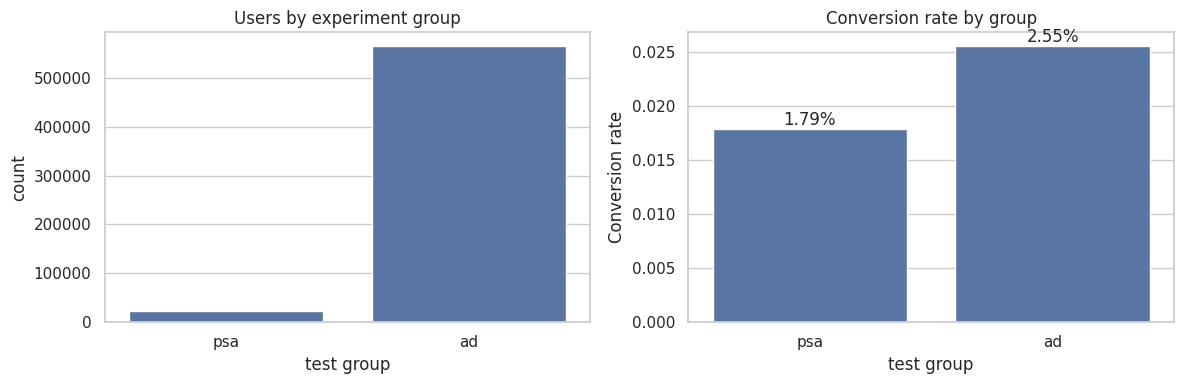

In [ ]:
fig, ax = plt.subplots(1,2,figsize=(12,4))
sns.countplot(data=marketing, x="test group", order=["psa","ad"], ax=ax[0])
ax[0].set_title("Users by experiment group")
rates_plot = marketing.groupby("test group")["converted"].mean().reindex(["psa","ad"])
sns.barplot(x=rates_plot.index, y=rates_plot.values, ax=ax[1])
ax[1].set_title("Conversion rate by group"); ax[1].set_ylabel("Conversion rate")
for i,v in enumerate(rates_plot.values): ax[1].text(i,v,f"{v:.2%}",ha="center",va="bottom")
plt.tight_layout(); plt.savefig(FIG/"marketing_group_conversion.png",dpi=160); plt.show()

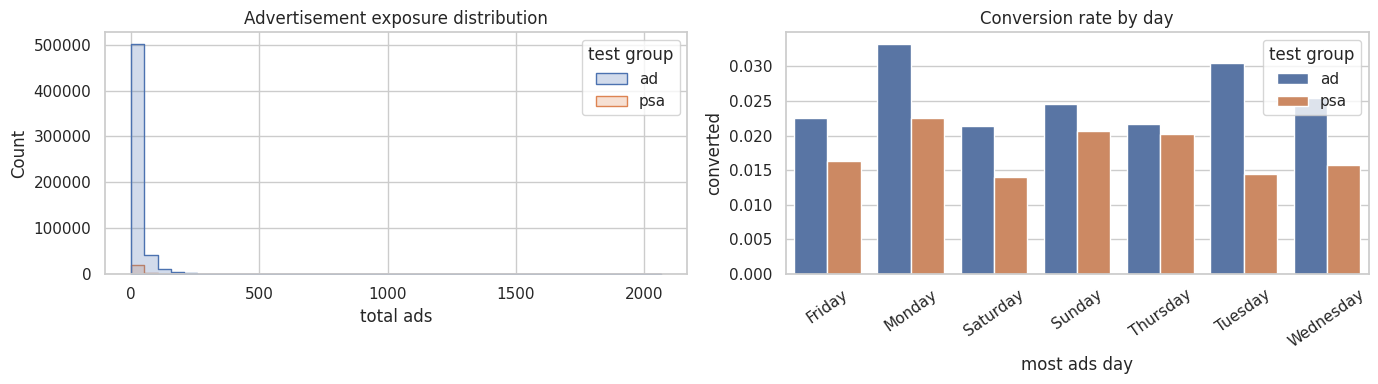

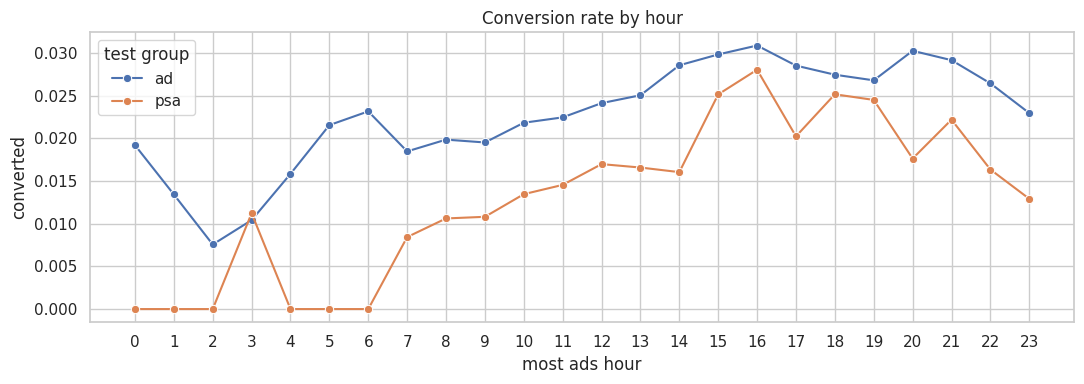

,exposure_band,test group,users,conversion_rate
0,1,ad,54298,0.0016
1,1,psa,2308,0.0013
2,2–3,ad,65239,0.0026
3,2–3,psa,3249,0.0022
4,4–5,ad,50425,0.0034
5,4–5,psa,2304,0.0052
6,6–10,ad,79537,0.0049
7,6–10,psa,3415,0.0067
8,11–20,ad,123334,0.0084
9,11–20,psa,4150,0.0082


In [ ]:
fig, ax = plt.subplots(1,2,figsize=(14,4))
sns.histplot(data=marketing,x="total ads",hue="test group",bins=40,element="step",ax=ax[0])
ax[0].set_title("Advertisement exposure distribution")
day = marketing.groupby(["most ads day","test group"])["converted"].mean().reset_index()
sns.barplot(data=day,x="most ads day",y="converted",hue="test group",ax=ax[1])
ax[1].set_title("Conversion rate by day"); ax[1].tick_params(axis="x",rotation=35)
plt.tight_layout(); plt.savefig(FIG/"marketing_exposure_day.png",dpi=160); plt.show()

hour = marketing.groupby(["most ads hour","test group"])["converted"].mean().reset_index()
plt.figure(figsize=(11,4))
sns.lineplot(data=hour,x="most ads hour",y="converted",hue="test group",marker="o")
plt.title("Conversion rate by hour"); plt.xticks(range(24)); plt.tight_layout()
plt.savefig(FIG/"marketing_conversion_hour.png",dpi=160); plt.show()

marketing["exposure_band"] = pd.cut(
    marketing["total ads"],[-np.inf,1,3,5,10,20,np.inf],
    labels=["1","2–3","4–5","6–10","11–20","21+"]
)
exposure = marketing.groupby(["exposure_band","test group"],observed=False)["converted"].agg(
    users="count",conversion_rate="mean").reset_index()
display(exposure)

## 6. A/B testing

**Treatment:** `ad`  
**Comparison group:** `psa`

- H₀: The conversion rates are equal.
- H₁: The conversion rates differ.
- Significance level: α = 0.05 (two-sided).

We will calculate conversion rates, absolute difference, relative uplift, two-proportion z-test, chi-square test, 95% confidence intervals and Cohen's h.

In [ ]:
group_summary = marketing.groupby("test group").agg(
    users=("user id","nunique"),
    conversions=("converted","sum"),
    conversion_rate=("converted","mean"),
    avg_ads_seen=("total ads","mean")
).reindex(["psa","ad"])
display(group_summary)

n0, x0 = int(group_summary.loc["psa","users"]), int(group_summary.loc["psa","conversions"])
n1, x1 = int(group_summary.loc["ad","users"]), int(group_summary.loc["ad","conversions"])
p0, p1 = x0/n0, x1/n1
diff = p1-p0
uplift = (diff/p0*100) if p0 else np.nan
print(f"PSA/control conversion rate: {p0:.4%}")
print(f"Ad/treatment conversion rate: {p1:.4%}")
print(f"Absolute difference (ad - psa): {diff:.4%}")
print(f"Relative uplift: {uplift:.2f}%")

,users,conversions,conversion_rate,avg_ads_seen
test group,,,,
psa,23524,420,0.0179,24.7611
ad,564577,14423,0.0255,24.8234


PSA/control conversion rate: 1.7854%
Ad/treatment conversion rate: 2.5547%
Absolute difference (ad - psa): 0.7692%
Relative uplift: 43.09%


In [ ]:
z_stat, z_p = proportions_ztest([x1,x0],[n1,n0],alternative="two-sided")
ci0 = proportion_confint(x0,n0,alpha=ALPHA,method="wilson")
ci1 = proportion_confint(x1,n1,alpha=ALPHA,method="wilson")
try:
    diff_ci = confint_proportions_2indep(
        x1,n1,x0,n0,method="newcomb",compare="diff",alpha=ALPHA
    )
except Exception:
    se = np.sqrt(p1*(1-p1)/n1 + p0*(1-p0)/n0)
    diff_ci = (diff-1.96*se,diff+1.96*se)

table = pd.crosstab(marketing["test group"],marketing["converted"]).reindex(
    index=["ad","psa"],columns=[0,1],fill_value=0)
chi2, chi_p, dof, expected = chi2_contingency(table)
cohens_h = proportion_effectsize(p1,p0)

results = {
    "alpha": ALPHA, "control_group":"psa", "treatment_group":"ad",
    "control_users":n0, "control_conversions":x0, "control_rate":p0,
    "control_ci95":[float(ci0[0]),float(ci0[1])],
    "treatment_users":n1, "treatment_conversions":x1, "treatment_rate":p1,
    "treatment_ci95":[float(ci1[0]),float(ci1[1])],
    "absolute_difference":diff, "difference_ci95":[float(diff_ci[0]),float(diff_ci[1])],
    "relative_uplift_percent":uplift, "z_statistic":float(z_stat),
    "z_p_value":float(z_p), "chi_square":float(chi2),
    "chi_square_p_value":float(chi_p), "cohens_h":float(cohens_h)
}
print(f"Two-proportion z-test: z={z_stat:.4f}, p={z_p:.6g}")
print(f"95% CI PSA rate: [{ci0[0]:.4%}, {ci0[1]:.4%}]")
print(f"95% CI Ad rate:  [{ci1[0]:.4%}, {ci1[1]:.4%}]")
print(f"95% CI difference (Ad - PSA): [{diff_ci[0]:.4%}, {diff_ci[1]:.4%}]")
print(f"Cohen's h: {cohens_h:.4f}")
print(f"Chi-square: statistic={chi2:.4f}, df={dof}, p={chi_p:.6g}")
print("Decision:", "Reject H0" if z_p < ALPHA else "Fail to reject H0")

Two-proportion z-test: z=7.3701, p=1.70528e-13
95% CI PSA rate: [1.6239%, 1.9627%]
95% CI Ad rate:  [2.5138%, 2.5961%]
95% CI difference (Ad - PSA): [0.5873%, 0.9360%]
Cohen's h: 0.0530
Chi-square: statistic=54.0058, df=1, p=1.99896e-13
Decision: Reject H0


## 7. Power and sample-size planning

In [ ]:
power_model = NormalIndPower()
observed_power = power_model.power(
    effect_size=abs(cohens_h), nobs1=n1, alpha=ALPHA,
    ratio=n0/n1, alternative="two-sided"
) if abs(cohens_h)>0 else np.nan
print(f"Descriptive power under observed effect: {observed_power:.4f}")
print("Post-hoc power is descriptive; do not use it instead of the p-value or confidence interval.")

# Example future experiment planning assumption: detect a 10% relative uplift.
mde_relative = 0.10
target_p1 = min(p0*(1+mde_relative),0.999999)
planning_effect = abs(proportion_effectsize(target_p1,p0))
required_n = power_model.solve_power(
    effect_size=planning_effect,power=0.80,alpha=ALPHA,
    ratio=1.0,alternative="two-sided"
)
print(f"Planning assumption: {mde_relative:.0%} relative uplift from PSA baseline")
print(f"Baseline={p0:.4%}; target={target_p1:.4%}")
print(f"Approx. required sample size per group for 80% power: {np.ceil(required_n):,.0f}")

Descriptive power under observed effect: 1.0000
Post-hoc power is descriptive; do not use it instead of the p-value or confidence interval.
Planning assumption: 10% relative uplift from PSA baseline
Baseline=1.7854%; target=1.9640%
Approx. required sample size per group for 80% power: 90,537


## 8. Business interpretation

In [ ]:
print(f"PSA conversion rate: {p0:.2%}")
print(f"Ad conversion rate: {p1:.2%}")
print(f"Absolute difference: {diff:.2%}")
print(f"Relative uplift: {uplift:.2f}%")
print(f"95% CI for difference: [{diff_ci[0]:.2%}, {diff_ci[1]:.2%}]")
print(f"Z-test p-value: {z_p:.6g}")
if z_p < ALPHA:
    print("The conversion rates differ statistically at the 5% level.")
else:
    print("There is insufficient evidence of a conversion-rate difference at the 5% level.")
print("Assess business value using the effect size, confidence interval, campaign costs and margin—not p-value alone.")
print("The causal interpretation assumes valid random assignment, consistent measurement and no interference.")

PSA conversion rate: 1.79%
Ad conversion rate: 2.55%
Absolute difference: 0.77%
Relative uplift: 43.09%
95% CI for difference: [0.59%, 0.94%]
Z-test p-value: 1.70528e-13
The conversion rates differ statistically at the 5% level.
Assess business value using the effect size, confidence interval, campaign costs and margin—not p-value alone.
The causal interpretation assumes valid random assignment, consistent measurement and no interference.


## 9. Online Retail: inspect and clean for sales EDA

In [ ]:
print("Columns:",retail_raw.columns.tolist())
print("Missing values:\n",retail_raw.isna().sum())
print("Exact duplicate rows:",retail_raw.duplicated().sum())
display(retail_raw.describe(include="all").T)

Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
Missing values:
 InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
Exact duplicate rows: 5268


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,"541,909.0000","25,900.0000","573,585.0000","1,114.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,"541,909.0000",NaN,NaN,NaN,9.5522,"-80,995.0000",1.0000,3.0000,10.0000,"80,995.0000",218.0812
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,"541,909.0000",NaN,NaN,NaN,4.6111,"-11,062.0600",1.2500,2.0800,4.1300,"38,970.0000",96.7599
CustomerID,"406,829.0000",NaN,NaN,NaN,"15,287.6906","12,346.0000","13,953.0000","15,152.0000","16,791.0000","18,287.0000","1,713.6003"
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
retail = retail_raw.copy()
retail.columns = [str(c).strip() for c in retail.columns]
required = ["InvoiceNo","StockCode","Description","Quantity","InvoiceDate","UnitPrice","CustomerID","Country"]
missing = [c for c in required if c not in retail.columns]
if missing: raise ValueError(f"Missing expected retail columns: {missing}")
retail["InvoiceDate"] = pd.to_datetime(retail["InvoiceDate"],errors="coerce")
retail["Quantity"] = pd.to_numeric(retail["Quantity"],errors="coerce")
retail["UnitPrice"] = pd.to_numeric(retail["UnitPrice"],errors="coerce")
retail["CustomerID"] = pd.to_numeric(retail["CustomerID"],errors="coerce")
retail["Revenue"] = retail["Quantity"]*retail["UnitPrice"]
retail = retail.drop_duplicates().copy()
retail["is_cancellation_invoice"] = retail["InvoiceNo"].astype(str).str.startswith("C",na=False)
retail["is_negative_quantity"] = retail["Quantity"]<0
retail["is_nonpositive_price"] = retail["UnitPrice"]<=0
print("Cancellation rows:",int(retail["is_cancellation_invoice"].sum()))
print("Negative quantity rows:",int(retail["is_negative_quantity"].sum()))
print("Non-positive price rows:",int(retail["is_nonpositive_price"].sum()))
print("Rows missing CustomerID:",int(retail["CustomerID"].isna().sum()))

# Positive valid sales subset for descriptive sales analysis. Original cleaned retail remains for audit.
retail_sales = retail[
    retail["InvoiceDate"].notna() & retail["CustomerID"].notna() &
    (~retail["is_cancellation_invoice"]) &
    (retail["Quantity"]>0) & (retail["UnitPrice"]>0)
].copy()
retail_sales["CustomerID"] = retail_sales["CustomerID"].astype("int64")
retail_sales["InvoiceMonth"] = retail_sales["InvoiceDate"].dt.to_period("M").astype(str)
retail_sales["InvoiceYear"] = retail_sales["InvoiceDate"].dt.year
retail_sales["InvoiceWeekday"] = retail_sales["InvoiceDate"].dt.day_name()
retail_sales["InvoiceHour"] = retail_sales["InvoiceDate"].dt.hour
print("Positive sales rows:",retail_sales.shape)
print("Customers:",retail_sales["CustomerID"].nunique())
print("Invoices:",retail_sales["InvoiceNo"].nunique())
print("Positive-sales revenue: £{:,.2f}".format(retail_sales["Revenue"].sum()))
display(retail_sales.head())

Cancellation rows: 9251
Negative quantity rows: 10587
Non-positive price rows: 2512
Rows missing CustomerID: 135037
Positive sales rows: (392692, 16)
Customers: 4338
Invoices: 18532
Positive-sales revenue: £8,887,208.89


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,is_cancellation_invoice,is_negative_quantity,is_nonpositive_price,InvoiceMonth,InvoiceYear,InvoiceWeekday,InvoiceHour
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.5500,17850,United Kingdom,15.3000,False,False,False,2010-12,2010,Wednesday,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.3900,17850,United Kingdom,20.3400,False,False,False,2010-12,2010,Wednesday,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.7500,17850,United Kingdom,22.0000,False,False,False,2010-12,2010,Wednesday,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.3900,17850,United Kingdom,20.3400,False,False,False,2010-12,2010,Wednesday,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.3900,17850,United Kingdom,20.3400,False,False,False,2010-12,2010,Wednesday,8


## 10. Online Retail EDA

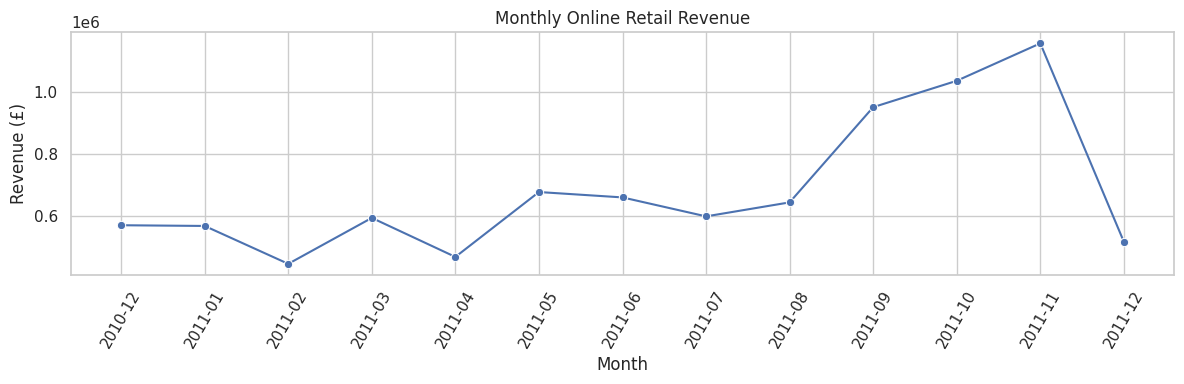

,InvoiceMonth,revenue,orders,customers
0,2010-12,"570,422.7300",1400,885
1,2011-01,"568,101.3100",987,741
2,2011-02,"446,084.9200",997,758
3,2011-03,"594,081.7600",1321,974
4,2011-04,"468,374.3310",1149,856
5,2011-05,"677,355.1500",1555,1056
6,2011-06,"660,046.0500",1393,991
7,2011-07,"598,962.9010",1331,949
8,2011-08,"644,051.0400",1280,935
9,2011-09,"950,690.2020",1755,1266


In [ ]:
monthly = retail_sales.groupby("InvoiceMonth").agg(
    revenue=("Revenue","sum"), orders=("InvoiceNo","nunique"),
    customers=("CustomerID","nunique")
).reset_index()
plt.figure(figsize=(12,4))
sns.lineplot(data=monthly,x="InvoiceMonth",y="revenue",marker="o")
plt.title("Monthly Online Retail Revenue"); plt.xlabel("Month"); plt.ylabel("Revenue (£)")
plt.xticks(rotation=60); plt.tight_layout()
plt.savefig(FIG/"retail_monthly_revenue.png",dpi=160); plt.show()
display(monthly)

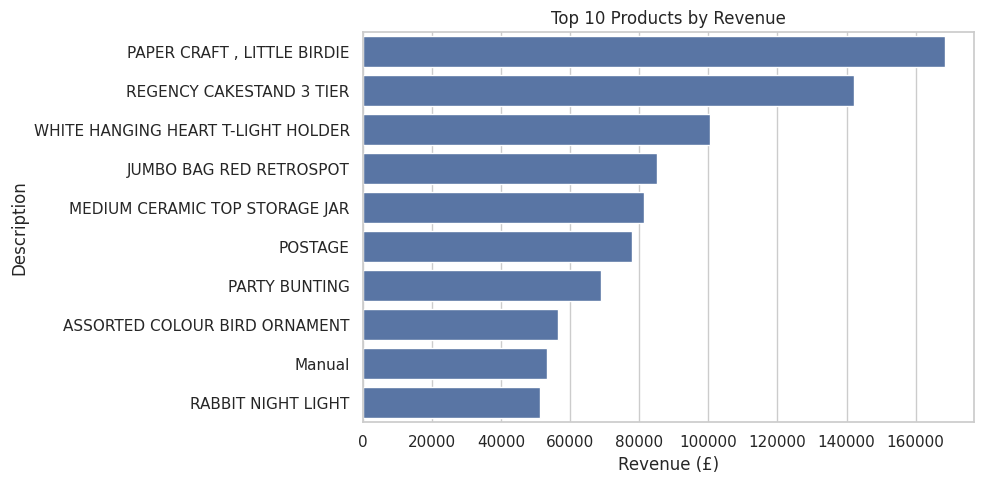

,Description,revenue,quantity
0,"PAPER CRAFT , LITTLE BIRDIE","168,469.6000",80995
1,REGENCY CAKESTAND 3 TIER,"142,264.7500",12374
2,WHITE HANGING HEART T-LIGHT HOLDER,"100,392.1000",36706
3,JUMBO BAG RED RETROSPOT,"85,040.5400",46078
4,MEDIUM CERAMIC TOP STORAGE JAR,"81,416.7300",77916
5,POSTAGE,"77,803.9600",3120
6,PARTY BUNTING,"68,785.2300",15279
7,ASSORTED COLOUR BIRD ORNAMENT,"56,413.0300",35263
8,Manual,"53,419.9300",6933
9,RABBIT NIGHT LIGHT,"51,251.2400",27153


In [ ]:
top_products = retail_sales.groupby("Description").agg(
    revenue=("Revenue","sum"),quantity=("Quantity","sum")
).sort_values("revenue",ascending=False).head(10).reset_index()
plt.figure(figsize=(10,5))
sns.barplot(data=top_products,y="Description",x="revenue")
plt.title("Top 10 Products by Revenue"); plt.xlabel("Revenue (£)")
plt.tight_layout(); plt.savefig(FIG/"retail_top_products.png",dpi=160); plt.show()
display(top_products)

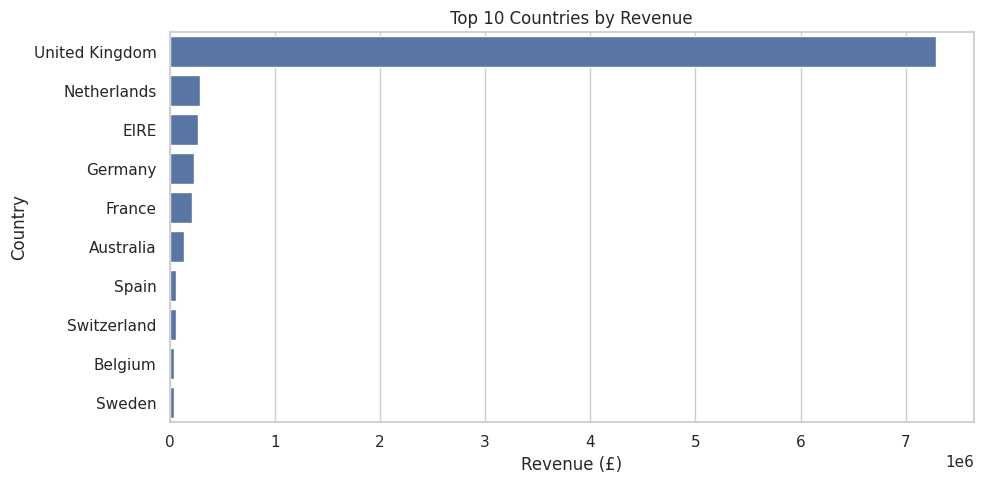

,Country,revenue,orders,customers
0,United Kingdom,"7,285,024.6440",16646,3920
1,Netherlands,"285,446.3400",94,9
2,EIRE,"265,262.4600",260,3
3,Germany,"228,678.4000",457,94
4,France,"208,934.3100",389,87
5,Australia,"138,453.8100",57,9
6,Spain,"61,558.5600",90,30
7,Switzerland,"56,443.9500",51,21
8,Belgium,"41,196.3400",98,25
9,Sweden,"38,367.8300",36,8


Average order value: £479.56
Median order value: £302.57
Average revenue per customer: £2,048.69


In [ ]:
country = retail_sales.groupby("Country").agg(
    revenue=("Revenue","sum"),orders=("InvoiceNo","nunique"),
    customers=("CustomerID","nunique")
).sort_values("revenue",ascending=False).head(10).reset_index()
plt.figure(figsize=(10,5))
sns.barplot(data=country,y="Country",x="revenue")
plt.title("Top 10 Countries by Revenue"); plt.xlabel("Revenue (£)")
plt.tight_layout(); plt.savefig(FIG/"retail_top_countries.png",dpi=160); plt.show()
display(country)

invoice_values = retail_sales.groupby("InvoiceNo")["Revenue"].sum()
customer_spend = retail_sales.groupby("CustomerID")["Revenue"].sum()
print(f"Average order value: £{invoice_values.mean():,.2f}")
print(f"Median order value: £{invoice_values.median():,.2f}")
print(f"Average revenue per customer: £{customer_spend.mean():,.2f}")

## 11. Save results and download outputs

In [ ]:
marketing.to_csv(OUT/"marketing_clean.csv",index=False)
retail_sales.to_csv(OUT/"online_retail_positive_sales_clean.csv",index=False)
group_summary.to_csv(MET/"ab_group_summary.csv")
monthly.to_csv(MET/"retail_monthly_summary.csv",index=False)
top_products.to_csv(MET/"retail_top_products.csv",index=False)
country.to_csv(MET/"retail_top_countries.csv",index=False)
exposure.to_csv(MET/"marketing_exposure_conversion.csv",index=False)
with open(MET/"ab_testing_results.json","w") as f:
    json.dump(results,f,indent=2)
print("Saved files:")
for p in sorted(OUT.rglob("*")):
    if p.is_file(): print(p)

Saved files:
outputs/figures/marketing_conversion_hour.png
outputs/figures/marketing_exposure_day.png
outputs/figures/marketing_group_conversion.png
outputs/figures/retail_monthly_revenue.png
outputs/figures/retail_top_countries.png
outputs/figures/retail_top_products.png
outputs/marketing_clean.csv
outputs/metrics/ab_group_summary.csv
outputs/metrics/ab_testing_results.json
outputs/metrics/marketing_exposure_conversion.csv
outputs/metrics/retail_monthly_summary.csv
outputs/metrics/retail_top_countries.csv
outputs/metrics/retail_top_products.csv
outputs/online_retail_positive_sales_clean.csv


In [ ]:
from google.colab import files
zip_name = "ab_testing_phases_1_to_3_outputs.zip"
with zipfile.ZipFile(zip_name,"w",zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob("*"):
        if p.is_file(): z.write(p,arcname=str(p))
files.download(zip_name)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Before proceeding to RFM and K-Means

Review the actual A/B test outputs and cleaning decisions first.

Remember:
- `ad` is treated as the treatment group and `psa` as the comparison group.
- The z-test p-value alone is not enough; interpret the confidence interval and effect size.
- Statistical significance is not the same as business value.
- The Online Retail dataset is a separate dataset; do not connect it to marketing experiment users.
- Cancellation invoices, returns and invalid prices were counted and retained in the audit dataframe, while the positive-sales subset was used for sales EDA.

In [ ]:

# ==========================================
# A/B TESTING: SAMPLE RATIO AND RESULT VALIDATION
# ==========================================

from scipy.stats import binomtest
import numpy as np

# Group sizes
N = len(marketing)
n_ad = (marketing["test group"] == "ad").sum()
n_psa = (marketing["test group"] == "psa").sum()

# Observed allocation
ad_share = n_ad / N
psa_share = n_psa / N

print("SAMPLE RATIO VALIDATION")
print("-" * 40)
print(f"Total users: {N:,}")
print(f"Ad users: {n_ad:,} ({ad_share:.2%})")
print(f"PSA users: {n_psa:,} ({psa_share:.2%})")

# Test against an assumed 96:4 allocation
expected_ad_share = 0.96

srm_test = binomtest(
    n_ad,
    n=N,
    p=expected_ad_share
)

print("\nSAMPLE RATIO MISMATCH TEST")
print("-" * 40)
print(f"Expected Ad allocation: 96%")
print(f"Observed Ad allocation: {ad_share:.4%}")
print(f"Binomial test p-value: {srm_test.pvalue:.6f}")

if srm_test.pvalue < 0.05:
    print("Potential sample ratio mismatch detected.")
else:
    print("No evidence of mismatch against the assumed 96:4 allocation.")

# Check unique users
print("\nDATA QUALITY")
print("-" * 40)
print("Unique users:", marketing["user id"].nunique())
print("Duplicate user IDs:", marketing["user id"].duplicated().sum())
print("Missing values:", marketing.isna().sum().sum())

# Validate conversion differences
p_ad = marketing.loc[
    marketing["test group"] == "ad", "converted"
].mean()

p_psa = marketing.loc[
    marketing["test group"] == "psa", "converted"
].mean()

print("\nCONVERSION COMPARISON")
print("-" * 40)
print(f"Ad conversion rate: {p_ad:.4%}")
print(f"PSA conversion rate: {p_psa:.4%}")
print(f"Absolute difference: {(p_ad-p_psa):.4%}")
print(f"Relative uplift: {((p_ad/p_psa)-1)*100:.2f}%")

print("\nVALIDATION COMPLETE")


SAMPLE RATIO VALIDATION
----------------------------------------
Total users: 588,101
Ad users: 564,577 (96.00%)
PSA users: 23,524 (4.00%)

SAMPLE RATIO MISMATCH TEST
----------------------------------------
Expected Ad allocation: 96%
Observed Ad allocation: 96.0000%
Binomial test p-value: 1.000000
No evidence of mismatch against the assumed 96:4 allocation.

DATA QUALITY
----------------------------------------
Unique users: 588101
Duplicate user IDs: 0
Missing values: 0

CONVERSION COMPARISON
----------------------------------------
Ad conversion rate: 2.5547%
PSA conversion rate: 1.7854%
Absolute difference: 0.7692%
Relative uplift: 43.09%

VALIDATION COMPLETE
